In [ ]:
## Plot seasonal cycle of VPD and PAR at flux tower sites compared to FATES
## use precip at each site to find average dry season and indicate on figure with light tan bar

In [1]:
import numpy as np
#
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
#
## this next library contains some helper functions for reshaping FATES variables into easier to work with dimensions
import ctsm_py.fates_xarray_funcs as fa       
#
import textwrap
from cmcrameri import cm
import cartopy
import cartopy.crs as ccrs
from cartopy.io.shapereader import Reader
import pandas as pd
from scipy.ndimage import uniform_filter1d


ERROR 1: PROJ: proj_create_from_database: Open of /global/homes/j/jkowalcz/.conda/envs/myenv/share/proj failed


In [2]:
# read in FATES output
tag='hydro_comp_bmort_kmax_tune_sapflow_kmax3_5xHR_fixSLA_vcmax40.55_fixHR_branch'
path='/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/SummaryFiles/'

file1=tag+'.elm.h1.01.cat.nc'
file2=tag+'.elm.h1.02.cat.nc'
file3=tag+'.elm.h1.03.cat.nc'
file4=tag+'.elm.h1.04.cat.nc'
file5=tag+'.elm.h1.05.cat.nc'
file6=tag+'.elm.h1.06.cat.nc'
file7=tag+'.elm.h1.07.cat.nc'
file8=tag+'.elm.h1.08.cat.nc'
file9=tag+'.elm.h1.09.cat.nc'
file10=tag+'.elm.h1.10.cat.nc'
file11=tag+'.elm.h1.11.cat.nc'
file12=tag+'.elm.h1.12.cat.nc'

chunk_size=100
d1 = xr.open_dataset(path+file1,chunks={'time': chunk_size})
d2 = xr.open_dataset(path+file2,chunks={'time': chunk_size})
d3 = xr.open_dataset(path+file3,chunks={'time': chunk_size})
d4 = xr.open_dataset(path+file4,chunks={'time': chunk_size})
d5 = xr.open_dataset(path+file5,chunks={'time': chunk_size})
d6 = xr.open_dataset(path+file6,chunks={'time': chunk_size})
d7 = xr.open_dataset(path+file7,chunks={'time': chunk_size})
d8 = xr.open_dataset(path+file8,chunks={'time': chunk_size})
d9 = xr.open_dataset(path+file9,chunks={'time': chunk_size})
d10 = xr.open_dataset(path+file10,chunks={'time': chunk_size})
d11 = xr.open_dataset(path+file11,chunks={'time': chunk_size})
d12 = xr.open_dataset(path+file12,chunks={'time': chunk_size})

In [3]:
rad1=d1.FSDS.groupby("time.dayofyear").mean()
rad2=d2.FSDS.groupby("time.dayofyear").mean()
rad3=d3.FSDS.groupby("time.dayofyear").mean()
rad4=d4.FSDS.groupby("time.dayofyear").mean()
rad5=d5.FSDS.groupby("time.dayofyear").mean()
rad6=d6.FSDS.groupby("time.dayofyear").mean()
rad7=d7.FSDS.groupby("time.dayofyear").mean()
rad8=d8.FSDS.groupby("time.dayofyear").mean()
rad9=d9.FSDS.groupby("time.dayofyear").mean()
rad10=d10.FSDS.groupby("time.dayofyear").mean()
rad11=d11.FSDS.groupby("time.dayofyear").mean()
rad12=d12.FSDS.groupby("time.dayofyear").mean()

In [4]:
# atmospheric incident solar radiation
# W/m2
fates_rad= xr.concat([rad1,rad2, rad3, rad4, rad5, rad6, rad7, rad8, rad9, rad10, rad11, rad12], dim="dayofyear")

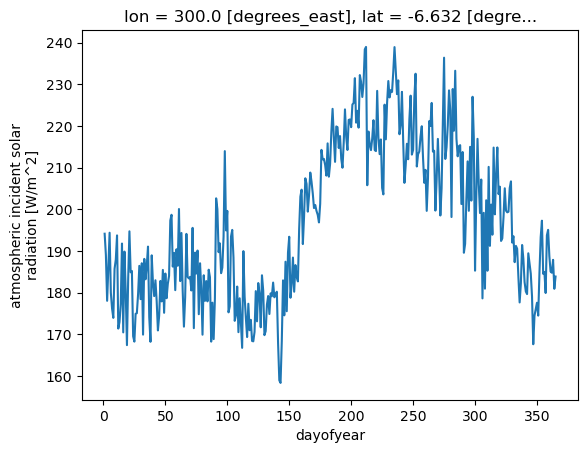

In [5]:
fates_rad.isel(lat=10).isel(lon=10).plot(x="dayofyear")

In [6]:
qbot1=d1.QBOT.groupby("time.dayofyear").mean()
qbot2=d2.QBOT.groupby("time.dayofyear").mean()
qbot3=d3.QBOT.groupby("time.dayofyear").mean()
qbot4=d4.QBOT.groupby("time.dayofyear").mean()
qbot5=d5.QBOT.groupby("time.dayofyear").mean()
qbot6=d6.QBOT.groupby("time.dayofyear").mean()
qbot7=d7.QBOT.groupby("time.dayofyear").mean()
qbot8=d8.QBOT.groupby("time.dayofyear").mean()
qbot9=d9.QBOT.groupby("time.dayofyear").mean()
qbot10=d10.QBOT.groupby("time.dayofyear").mean()
qbot11=d11.QBOT.groupby("time.dayofyear").mean()
qbot12=d12.QBOT.groupby("time.dayofyear").mean()

In [7]:
fates_qbot= xr.concat([qbot1, qbot2, qbot3, qbot4, qbot5, qbot6, qbot7, qbot8, qbot9, qbot10, qbot11, qbot12], dim="dayofyear")

In [8]:
tbot1=d1.TBOT.groupby("time.dayofyear").mean()
tbot2=d2.TBOT.groupby("time.dayofyear").mean()
tbot3=d3.TBOT.groupby("time.dayofyear").mean()
tbot4=d4.TBOT.groupby("time.dayofyear").mean()
tbot5=d5.TBOT.groupby("time.dayofyear").mean()
tbot6=d6.TBOT.groupby("time.dayofyear").mean()
tbot7=d7.TBOT.groupby("time.dayofyear").mean()
tbot8=d8.TBOT.groupby("time.dayofyear").mean()
tbot9=d9.TBOT.groupby("time.dayofyear").mean()
tbot10=d10.TBOT.groupby("time.dayofyear").mean()
tbot11=d11.TBOT.groupby("time.dayofyear").mean()
tbot12=d12.TBOT.groupby("time.dayofyear").mean()

In [9]:
fates_tbot= xr.concat([tbot1, tbot2, tbot3, tbot4, tbot5, tbot6, tbot7, tbot8, tbot9, tbot10, tbot11, tbot12], dim="dayofyear")

In [10]:
# calculate VPD

# Tetens eq.
esat=0.61078*np.exp((17.269*(fates_tbot-273.15))/((fates_tbot-273.15)+237.3))

ea = (1204*fates_qbot*(fates_tbot-273.15)/216.7)
fates_vpd=esat - ea # kPa

In [11]:
## Paracou, French Guiana
par_lat=5.2787
par_lon=360.-52.9248
par_dt=-3 ## time in CSV file is local time, so we don't need to apply this to observed data

### Tapajos (TAP) - Brazil - UTC-3
tap_lat=-3.3  
tap_lon=305.0
tap_dt=-4 # solar time is UTC - 3.5
tap_dt2=-3 # flux tower data timestamp is beginning of measurement interval

## Tanguro - Brazil
tan_lat = -13.08 
tan_lon = 307.59
tan_dt = -4 # GMT-4 -- for FATES simulations
tan_dt2 = 0 ## flux tower data is in local time

## K34 -- Brazil
k34_lat = -2.6091
k34_lon = 360.-60.2093
k34_dt = -4

In [39]:
fates_days=np.linspace(1,365,365,dtype=np.int32)

In [14]:
## For calculating dry season from FATES 
file0=tag+'.elm.h0.cat.nc' # should be daily output
d0 = xr.open_dataset(path+file0)

In [16]:
# Define sites and real-world coordinates
site_names = ['par', 'tap', 'tan', 'k34']
target_lats = [par_lat, tap_lat, tan_lat, k34_lat]
target_lons = [par_lon, tap_lon, tan_lon, k34_lon]

# Wrap in DataArrays along a new 'site' dimension
site_lats = xr.DataArray(target_lats, dims="site", coords={"site": site_names})
site_lons = xr.DataArray(target_lons, dims="site", coords={"site": site_names})

# Extract all sites at once with nearest-neighbor lookup
all_sites_rad = fates_rad.sel(
    lat=site_lats, 
    lon=site_lons, 
    method="nearest"
)
all_sites_vpd = fates_vpd.sel(
    lat=site_lats, 
    lon=site_lons, 
    method="nearest"
)

In [35]:
all_sites_rad

<xarray.DataArray 'FSDS' (dayofyear: 365, site: 4)>
dask.array<transpose, shape=(365, 4), dtype=float32, chunksize=(1, 4), chunktype=numpy.ndarray>
Coordinates:
    lon        (site) float32 307.5 305.0 307.5 300.0
    lat        (site) float32 4.737 -2.842 -12.32 -2.842
  * dayofyear  (dayofyear) int64 1 2 3 4 5 6 7 8 ... 359 360 361 362 363 364 365
  * site       (site) <U3 'par' 'tap' 'tan' 'k34'
Attributes:
    long_name:     atmospheric incident solar radiation
    units:         W/m^2
    cell_methods:  time: mean

In [17]:
# d0.RAIN in mm/s
# get monthly average rainfall
fates_avg_rain = d0.RAIN.groupby('time.month').mean(dim='time')
# multiply by seconds per month to get total monthly rainfall in mm
sec_per_month=3.156e+7/12.
gswp_rain=sec_per_month*fates_avg_rain.sel(
    lat=site_lats, 
    lon=site_lons, 
    method="nearest"
).data

In [18]:
## Get flux tower data

In [19]:
## read in Paracou flux tower data
# Note: ICOS dataset is 2017-2024
# we want 2004-2014 to overlap with FATES forcing (1990-2014)

flx_path='/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/Benchmarks/FluxTower/'
par_file='Guyaflux/data.csv'
# missing data in this file is empty -- automatically converted to NaN by Pandas

par_df = pd.read_csv(flx_path+par_file, sep=',')

# =====================================================================
# 1. TIME RESOLUTION & ROW COUNTER DIAGNOSTIC
# =====================================================================
par_raw_counts_per_day = par_df.groupby(['Year', 'Julian Day']).size()
avg_par_raw_rows = par_raw_counts_per_day.mean()

print("--- Paracou Temporal Resolution Check ---")
print(f"Average raw data rows per day: {avg_par_raw_rows:.2f}")

if 22 <= avg_par_raw_rows <= 26:
    print("-> Resolution looks to be HOURLY (Target perfect day = 24 rows)")
    print("-> Suggested diurnal filter threshold: 19 rows (~80%)")
elif 46 <= avg_par_raw_rows <= 50:
    print("-> Resolution looks to be HALF-HOURLY (Target perfect day = 48 rows)")
    print("-> Suggested diurnal filter threshold: 38 rows (~80%)")
else:
    print("-> Warning: Unexpected row count. Verify dataset formatting.")
print("------------------------------------------\n")

--- Paracou Temporal Resolution Check ---
Average raw data rows per day: 48.00
-> Resolution looks to be HALF-HOURLY (Target perfect day = 48 rows)
-> Suggested diurnal filter threshold: 38 rows (~80%)
------------------------------------------



In [20]:
# =====================================================================
# 2. RUN SEPARATE DIURNAL COVERAGE FILTERS
# =====================================================================
# Count valid timesteps per day (Pandas ignores NaNs automatically)
par_df['Rg_Counts'] = par_df.groupby(['Year', 'Julian Day'])['Rg'].transform('count')
par_df['VPD_Counts']  = par_df.groupby(['Year', 'Julian Day'])['VPD55'].transform('count')

diurnal_mask_rg = par_df['Rg_Counts'] >= 38
diurnal_mask_vpd  = par_df['VPD_Counts'] >= 38

# =====================================================================
# 3. COMBINE WITH LEAP DAY FILTER FOR SEPARATE SUBSETS
# =====================================================================
is_leap_year = (par_df['Year'] % 4 == 0)
is_leap_day = (par_df['Julian Day'] == 60)
not_leap_day = ~(is_leap_year & is_leap_day)

keep_rg_mask = not_leap_day & diurnal_mask_rg
keep_vpd_mask  = not_leap_day & diurnal_mask_vpd

# Extract separate subsets
df_rg_sub = par_df[keep_rg_mask].copy()
df_vpd_sub  = par_df[keep_vpd_mask].copy()

# =====================================================================
# 4. SHIFT THE REMAINING DAYS IN LEAP YEARS (For both streams)
# =====================================================================
# GPP Stream Shift
par_year_rg = df_rg_sub['Year'].values
raw_jd_rg   = df_rg_sub['Julian Day'].values
par_jd_rg   = np.where((par_year_rg % 4 == 0) & (raw_jd_rg > 60), raw_jd_rg - 1, raw_jd_rg)

# LH Stream Shift
par_year_vpd = df_vpd_sub['Year'].values
raw_jd_vpd   = df_vpd_sub['Julian Day'].values
par_jd_vpd   = np.where((par_year_vpd % 4 == 0) & (raw_jd_vpd > 60), raw_jd_vpd - 1, raw_jd_vpd)

# Extract raw data arrays from their respective subsets
par_rg = df_rg_sub['Rg'].values # W/m2
par_vpd   = df_vpd_sub['VPD55'].values #kPa

# =====================================================================
# 5. CALCULATE YEARLY CYCLE WITH SEPARATE STREAM INDICES
# =====================================================================
# Master day coordinate array is always 1 to 365
par_jd = np.arange(1, 366)

par_avg_rad = np.zeros(len(par_jd))
par_std_rad = np.zeros(len(par_jd))
par_avg_vpd = np.zeros(len(par_jd))
par_std_vpd = np.zeros(len(par_jd))

for i in range(len(par_jd)):
    # Find indices using separate stream day arrays
    ind_rg = np.where(par_jd_rg == par_jd[i])
    ind_vpd  = np.where(par_jd_vpd == par_jd[i])
    
    if len(ind_rg[0]) > 0:
        par_avg_rad[i] = np.nanmean(par_rg[ind_rg[0]]) 
        par_std_rad[i] = np.nanstd(par_rg[ind_rg[0]]) 
    else:
        par_avg_rad[i], par_std_rg[i] = np.nan, np.nan
        par_avg_rda[i], par_std_rg[i] = np.nan, np.nan
        
    if len(ind_vpd[0]) > 0:
        par_avg_vpd[i]  = np.nanmean(par_vpd[ind_vpd[0]]) 
        par_std_vpd[i]  = np.nanstd(par_vpd[ind_vpd[0]]) 
    else:
        par_avg_vpd[i], par_std_vpd[i] = np.nan, np.nan

In [21]:
## read in Tapajos flux tower data

flx_path='/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/Benchmarks/FluxTower/'
tap_file='Tapajos/Tapajos_flux_tower_data_EC.prerelease/km67.eddyflux.txt' 

tap_df = pd.read_csv(flx_path+tap_file, sep=',')

# Missing data in the input file is indicated by 999.99
tap_df = tap_df.replace(999.99, np.nan) 

# =====================================================================
# TIME RESOLUTION & ROW COUNTER DIAGNOSTIC
# =====================================================================
# Calculate total raw rows per day across all years
raw_counts_per_day = tap_df.groupby(['YYYY', 'JD']).size()
avg_raw_rows = raw_counts_per_day.mean()

print("--- Tapajos Temporal Resolution Check ---")
print(f"Average raw data rows per day: {avg_raw_rows:.2f}")

if 22 <= avg_raw_rows <= 26:
    print("-> Resolution looks to be HOURLY (Target perfect day = 24 rows)")
    print("-> Suggested diurnal filter threshold: 19 rows (~80%)")
elif 46 <= avg_raw_rows <= 50:
    print("-> Resolution looks to be HALF-HOURLY (Target perfect day = 48 rows)")
    print("-> Suggested diurnal filter threshold: 38 rows (~80%)")
else:
    print("-> Warning: Unexpected row count. Verify dataset formatting.")
print("------------------------------------------\n")

--- Tapajos Temporal Resolution Check ---
Average raw data rows per day: 24.00
-> Resolution looks to be HOURLY (Target perfect day = 24 rows)
-> Suggested diurnal filter threshold: 19 rows (~80%)
------------------------------------------



In [43]:
tap_df.columns.tolist()

['hours',
 'jdstart.gmt',
 'YYYY',
 'JD',
 'HRMI',
 'ws',
 'wdir',
 't.c',
 'rh',
 'tson',
 'tasp',
 'fheat',
 'fmom',
 'co2',
 'fco2',
 'h2o.mmol.m',
 'fh2o',
 'h2o.mix',
 'pamb.pa',
 'H',
 'LHdry',
 'ustar',
 'ppm2umol',
 'netrad',
 'snetrad',
 'netrad.cal',
 'par',
 'spar1up',
 'par2up',
 'spar2up',
 'par1dn',
 'spar1dn',
 'par.cal',
 'tair1',
 'tair2',
 'tair3',
 'tair4',
 'tair5',
 'tair6',
 'tair7',
 'tair8',
 'ws1',
 'sws1',
 'ws2',
 'sws2',
 'ws3',
 'sws3',
 'ws4',
 'sws4',
 'rain',
 'tot.sun',
 'dif.sun',
 'e_sat',
 'RH.ec',
 'VPD.ec',
 'u',
 'v',
 'w',
 'u.std',
 'v.std',
 'w.std',
 'CO2col.wt',
 'storage.wt',
 'co2.pf.1',
 'co2.pf.2',
 'co2.pf.3',
 'co2.pf.4',
 'co2.pf.5',
 'co2.pf.6',
 'co2.pf.7',
 'co2.pf.8',
 'H2Ocol.wt',
 'H2Ostorage.wt',
 'h2o.pf.1',
 'h2o.pf.2',
 'h2o.pf.3',
 'h2o.pf.4',
 'h2o.pf.5',
 'h2o.pf.6',
 'h2o.pf.7',
 'h2o.pf.8',
 'nee',
 'nee.fill',
 'r',
 'gee',
 'par.fill',
 'TOA',
 'nee.fill.light',
 'r.light',
 'gee.fill.light',
 'stg.filled']

In [44]:

# =====================================================================
# 1. RUN DIURNAL COVERAGE FILTER FIRST
# =====================================================================
# Count valid timesteps for each variable independently per Day of Year (JD)
# (If 30-min data, require >= 38. If hourly, require >= 19)
tap_df['rad_Counts'] = tap_df.groupby(['YYYY', 'JD'])['par'].transform('count')
tap_df['vpd_Counts']  = tap_df.groupby(['YYYY', 'JD'])['VPD.ec'].transform('count')

diurnal_mask_rad = tap_df['rad_Counts'] >= 19
diurnal_mask_vpd  = tap_df['vpd_Counts'] >= 19

# =====================================================================
# 2. COMBINE WITH LEAP DAY FILTER FOR SEPARATE SUBSETS
# =====================================================================
is_leap_year = (tap_df['YYYY'] % 4 == 0)
is_leap_day = (tap_df['JD'] == 60)
not_leap_day = ~(is_leap_year & is_leap_day)

keep_rad_mask = not_leap_day & diurnal_mask_rad
keep_vpd_mask  = not_leap_day & diurnal_mask_vpd

# Extract separate subsets
df_rad_sub = tap_df[keep_rad_mask].copy()
df_vpd_sub  = tap_df[keep_vpd_mask].copy()

# =====================================================================
# 3. SHIFT THE REMAINING DAYS IN LEAP YEARS (For both streams)
# =====================================================================
tap_year_rad = df_rad_sub['YYYY'].values
raw_jd_rad = df_rad_sub['JD'].values
tap_jd_rad = np.where((tap_year_rad % 4 == 0) & (raw_jd_rad > 60), raw_jd_rad - 1, raw_jd_rad)

tap_year_vpd = df_vpd_sub['YYYY'].values
raw_jd_vpd = df_vpd_sub['JD'].values
tap_jd_vpd = np.where((tap_year_vpd % 4 == 0) & (raw_jd_vpd > 60), raw_jd_vpd - 1, raw_jd_vpd)

# Extract final raw arrays from their respective clean subsets
tap_rad = df_rad_sub['par'].values #umol/m2/s
tap_vpd = df_vpd_sub['VPD.ec'].values #kPa

# =====================================================================
# 4. CALCULATE YEARLY CYCLE WITH SEPARATE STREAM INDICES
# =====================================================================
# Master day array is always 1 to 365
tap_jd = np.arange(1, 366)

tap_avg_rad = np.zeros(len(tap_jd))
tap_std_rad = np.zeros(len(tap_jd))
tap_avg_vpd  = np.zeros(len(tap_jd))
tap_std_vpd  = np.zeros(len(tap_jd))

for i in range(len(tap_jd)): 
    # Find indices using separate stream day arrays
    ind_rad = np.where(tap_jd_rad == tap_jd[i])
    ind_vpd  = np.where(tap_jd_vpd == tap_jd[i])
    
    if len(ind_rad[0]) > 0:
        tap_avg_rad[i] = np.nanmean(tap_rad[ind_rad[0]]) 
        tap_std_rad[i] = np.nanstd(tap_rad[ind_rad[0]]) 
    else:
        tap_avg_rad[i], tap_std_rad[i] = np.nan, np.nan
        
    if len(ind_vpd[0]) > 0:
        tap_avg_vpd[i]  = np.nanmean(tap_vpd[ind_vpd[0]])
        tap_std_vpd[i]  = np.nanstd(tap_vpd[ind_vpd[0]])
    else:
        tap_avg_vpd[i], tap_std_vpd[i] = np.nan, np.nan

In [45]:
## read in Tanguro flux tower data

flx_path='/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/Benchmarks/FluxTower/'
tan_file='Tanguro/EC_Control_2014-2024_GAPFILLED_Final.csv'
# missing values are NaNs

# Read in data frame for Tanguro
tan_df = pd.read_csv(flx_path+tan_file, sep=',')

# =====================================================================
# TANGURO TIME RESOLUTION & ROW COUNTER DIAGNOSTIC
# =====================================================================
# Count total raw rows per calendar date across the entire timeseries
tan_raw_counts_per_day = tan_df.groupby(['Year', 'Day']).size()
avg_tan_raw_rows = tan_raw_counts_per_day.mean()

print("--- Tanguro Temporal Resolution Check ---")
print(f"Average raw data rows per day: {avg_tan_raw_rows:.2f}")

if 22 <= avg_tan_raw_rows <= 26:
    print("-> Resolution looks to be HOURLY (Target perfect day = 24 rows)")
    print("-> Suggested diurnal filter threshold: 19 rows (~80%)")
elif 46 <= avg_tan_raw_rows <= 50:
    print("-> Resolution looks to be HALF-HOURLY (Target perfect day = 48 rows)")
    print("-> Suggested diurnal filter threshold: 38 rows (~80%)")
else:
    print(f"-> Warning: Unexpected row count ({avg_tan_raw_rows:.1f}). Verify dataset structure.")
print("------------------------------------------\n")

/tmp/ipykernel_2268287/2034533611.py:8: DtypeWarning: Columns (113,114,213) have mixed types. Specify dtype option on import or set low_memory=False.
  tan_df = pd.read_csv(flx_path+tan_file, sep=',')


--- Tanguro Temporal Resolution Check ---
Average raw data rows per day: 48.00
-> Resolution looks to be HALF-HOURLY (Target perfect day = 48 rows)
-> Suggested diurnal filter threshold: 38 rows (~80%)
------------------------------------------



In [46]:
## calculate vpd
#tempK=tan_df['atm.tmp']
#spcHum=tan_df['atm.shv'] # kg/kg

## Tetens eq.
#esat=0.61078*np.exp((17.269*(tempK-273.15))/((tempK-273.15)+237.3))

#ea = (1204*spcHum*(tempK-273.15)/216.7)
#tan_df['vpd']=esat - ea

# Count valid timesteps per day for each variable
tan_df['vpd_Counts'] = tan_df.groupby(['Year', 'Day'])['VPD'].transform('count')
tan_df['rad_Counts'] = tan_df.groupby(['Year', 'Day'])['Rg'].transform('count')

# Create separate diurnal masks (e.g., require >= 38 periods out of 48)
diurnal_mask_vpd  = tan_df['vpd_Counts'] >= 38
diurnal_mask_rad = tan_df['rad_Counts'] >= 38

# 3. Combine with Leap Day Filter to create SEPARATE row masks
is_leap_year = (tan_df['Year'] % 4 == 0)
is_leap_day = (tan_df['Day'] == 60)
not_leap_day = ~(is_leap_year & is_leap_day)

keep_rad_mask = not_leap_day & diurnal_mask_rad
keep_vpd_mask  = not_leap_day & diurnal_mask_vpd

# 4. Extract separate cleaned subsets
df_rad_sub = tan_df[keep_rad_mask].copy()
df_vpd_sub  = tan_df[keep_vpd_mask].copy()

# =====================================================================
# 5. SHIFT THE REMAINING DAYS IN LEAP YEARS (Do this for both streams)
# =====================================================================
tan_year_rad = df_rad_sub['Year'].values
raw_jd_rad = df_rad_sub['Day'].values
jd_all_rad = np.where((tan_year_rad % 4 == 0) & (raw_jd_rad > 60), raw_jd_rad - 1, raw_jd_rad)

tan_year_vpd = df_vpd_sub['Year'].values
raw_jd_vpd = df_vpd_sub['Day'].values
jd_all_vpd = np.where((tan_year_vpd % 4 == 0) & (raw_jd_vpd > 60), raw_jd_vpd - 1, raw_jd_vpd)

# Extract your raw data arrays
tan_rad = df_rad_sub['Rg'].values 
tan_vpd  = df_vpd_sub['VPD'].values

# Your master 1-365 coordinate list for the loop remains the same
tan_jd = np.arange(1, 366)

# Initialize your empty 365-day arrays
tan_avg_rad = np.zeros(365)
tan_std_rad = np.zeros(365)
tan_avg_vpd = np.zeros(365)
tan_std_vpd = np.zeros(365)

for i in range(len(tan_jd)):
    # Find indices using the separate stream arrays
    ind_rad = np.where(jd_all_rad == tan_jd[i])
    ind_vpd = np.where(jd_all_vpd == tan_jd[i])
    
    if len(ind_rad[0]) > 0:
        tan_avg_rad[i] = np.nanmean(tan_rad[ind_rad[0]])
        tan_std_rad[i] = np.nanstd(tan_rad[ind_rad[0]])
    else:
        tan_avg_rad[i], tan_std_rad[i] = np.nan, np.nan
        
    if len(ind_vpd[0]) > 0:
        tan_avg_vpd[i] = np.nanmean(tan_vpd[ind_vpd[0]])
        tan_std_vpd[i] = np.nanstd(tan_vpd[ind_vpd[0]])
    else:
        tan_avg_vpd[i], tan_std_vpd[i] = np.nan, np.nan

In [47]:
## K34 site

flx_path='/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/Benchmarks/FluxTower/'
k34_file='K34/Prev/AMF_BR-Ma2_BASE_HH_1-5.csv'
# HH means records half-hourly
# Missing data records are indicated by the -9999 value.

# Read in K34 dataframe:
k34_df = pd.read_csv(flx_path+k34_file, sep=',', skiprows=2)

# 1. Pull the raw, unfiltered data from the dataframe
k34_rad_raw = k34_df['SW_IN_PI_F'].values #W/m2
k34_vpd_raw = k34_df['VPD_PI_F'].values  
timestamps_raw = k34_df['TIMESTAMP_START'].values

# Parse raw dates immediately so we have access to calendar Year and DOY
dt_raw = pd.to_datetime(timestamps_raw, format='%Y%m%d%H%M')

# =====================================================================
# K34 TIME RESOLUTION & ROW COUNTER DIAGNOSTIC
# =====================================================================
# Group the dataset by the calendar year and day extracted from dt_raw
k34_raw_counts_per_day = k34_df.groupby([dt_raw.year, dt_raw.dayofyear]).size()
avg_k34_raw_rows = k34_raw_counts_per_day.mean()

print("--- K34 Temporal Resolution Check ---")
print(f"Average raw data rows per day: {avg_k34_raw_rows:.2f}")

if 22 <= avg_k34_raw_rows <= 26:
    print("-> Resolution looks to be HOURLY (Target perfect day = 24 rows)")
    print("-> Suggested diurnal filter threshold: 19 rows (~80%)")
elif 46 <= avg_k34_raw_rows <= 50:
    print("-> Resolution looks to be HALF-HOURLY (Target perfect day = 48 rows)")
    print("-> Suggested diurnal filter threshold: 38 rows (~80%)")
else:
    print(f"-> Warning: Unexpected row count ({avg_k34_raw_rows:.1f}). Verify dataset structure.")
print("--------------------------------------\n")

--- K34 Temporal Resolution Check ---
Average raw data rows per day: 48.00
-> Resolution looks to be HALF-HOURLY (Target perfect day = 48 rows)
-> Suggested diurnal filter threshold: 38 rows (~80%)
--------------------------------------



In [48]:
# 2. RUN DIURNAL COVERAGE FILTER FIRST
df_check = pd.DataFrame({
    'rad': k34_rad_raw,
    'vpd' : k34_vpd_raw,
    'Year': dt_raw.year,
    'DOY': dt_raw.dayofyear
})
df_check['rad'] = df_check['rad'].replace(-9999, np.nan)
df_check['vpd'] = df_check['vpd'].replace(-9999, np.nan)

# Count valid timesteps for each variable independently
df_check['rad_Valid_Counts'] = df_check.groupby(['Year', 'DOY'])['rad'].transform('count')
df_check['vpd_Valid_Counts'] = df_check.groupby(['Year', 'DOY'])['vpd'].transform('count')

diurnal_mask_rad = df_check['rad_Valid_Counts'] >= 38
diurnal_mask_vpd  = df_check['vpd_Valid_Counts'] >= 38

# 3. COMBINE DIURNAL FILTER WITH VALID DATA FILTER (Row must be valid data AND pass diurnal threshold)
valid_rad_mask = (k34_rad_raw != -9999) & diurnal_mask_rad
valid_vpd_mask  = (k34_vpd_raw != -9999) & diurnal_mask_vpd

# 4. PARSE TIMESTAMPS AND APPLY LEAP DAY MASKS SEPARATELY
dt_rad = pd.to_datetime(timestamps_raw[valid_rad_mask], format='%Y%m%d%H%M')
keep_day_rad = ~((dt_rad.year % 4 == 0) & (dt_rad.dayofyear == 60))

k34_rad = k34_rad_raw[valid_rad_mask][keep_day_rad]

rad_year = dt_rad[keep_day_rad].year.values
rad_raw_doy = dt_rad[keep_day_rad].dayofyear.values
k34_doy_rad = np.where((rad_year % 4 == 0) & (rad_raw_doy > 60), rad_raw_doy - 1, rad_raw_doy)

dt_vpd = pd.to_datetime(timestamps_raw[valid_vpd_mask], format='%Y%m%d%H%M')
keep_day_vpd = ~((dt_vpd.year % 4 == 0) & (dt_vpd.dayofyear == 60))

k34_vpd = k34_vpd_raw[valid_vpd_mask][keep_day_vpd]

vpd_year = dt_vpd[keep_day_vpd].year.values
vpd_raw_doy = dt_vpd[keep_day_vpd].dayofyear.values
k34_doy_vpd = np.where((vpd_year % 4 == 0) & (vpd_raw_doy > 60), vpd_raw_doy - 1, vpd_raw_doy)


# =====================================================================
# 5. CALCULATE YEARLY CYCLE WITH SEPARATE STREAM INDICES
# =====================================================================
# Master day array is always 1 to 355
k34_jd = np.arange(1, 366)

k34_avg_rad = np.zeros(len(k34_jd))
k34_std_rad = np.zeros(len(k34_jd))
k34_avg_vpd  = np.zeros(len(k34_jd))
k34_std_vpd  = np.zeros(len(k34_jd))

for i in range(len(k34_jd)):  
    # Find indices using separate stream DOY arrays
    ind_rad = np.where(k34_doy_rad == k34_jd[i])
    ind_vpd  = np.where(k34_doy_vpd == k34_jd[i])
    
    if len(ind_rad[0]) > 0:
        k34_avg_rad[i] = np.nanmean(k34_rad[ind_rad[0]]) 
        k34_std_rad[i] = np.nanstd(k34_rad[ind_rad[0]]) 
    else:
        k34_avg_rad[i], k34_std_rad[i] = np.nan, np.nan
        
    if len(ind_vpd[0]) > 0:
        k34_avg_vpd[i]  = np.nanmean(k34_vpd[ind_vpd[0]])
        k34_std_vpd[i]  = np.nanstd(k34_vpd[ind_vpd[0]])
    else:
        k34_avg_vpd[i], k34_std_vpd[i] = np.nan, np.nan

In [49]:
## Plot everything!

In [50]:
par_ymin_rad=100
par_ymax_rad=300

k34_ymin_rad=100
k34_ymax_rad=300

tap_ymin_rad=100
tap_ymax_rad=300

tan_ymin_rad=100
tan_ymax_rad=300


In [58]:
par_ymin_vpd=0
par_ymax_vpd=3

k34_ymin_vpd=0
k34_ymax_vpd=3

tap_ymin_vpd=0
tap_ymax_vpd=3

tan_ymin_vpd=0
tan_ymax_vpd=3


In [ ]:
## Tavares et al (2023): dry season where monthly precip is below 100 mm
gswp_rain_par

In [ ]:
gswp_rain_k34

In [ ]:
gswp_rain_tap

In [ ]:
gswp_rain_tan

In [59]:
from matplotlib.patches import Rectangle
color='burlywood'
dpm=np.max(fates_days)/12.

gswp_par_dry_rad=Rectangle((9*dpm,par_ymin_rad),2*dpm,par_ymax_rad-par_ymin_rad, facecolor=color, alpha=0.5)
gswp_k34_dry_rad=Rectangle((7*dpm,k34_ymin_rad),3*dpm,k34_ymax_rad-k34_ymin_rad, facecolor=color, alpha=0.5)
gswp_tap_dry1_rad=Rectangle((0*dpm,tap_ymin_rad),1*dpm,tap_ymax_rad-tap_ymin_rad, facecolor=color, alpha=0.5)
gswp_tap_dry2_rad=Rectangle((8*dpm,tap_ymin_rad),4*dpm,tap_ymax_rad-tap_ymin_rad, facecolor=color, alpha=0.5)
gswp_tan_dry_rad=Rectangle((5*dpm,tan_ymin_rad),5*dpm,tan_ymax_rad-tan_ymin_rad, facecolor=color, alpha=0.5)

gswp_par_dry_vpd=Rectangle((9*dpm,par_ymin_vpd),2*dpm,par_ymax_vpd-par_ymin_vpd, facecolor=color, alpha=0.5)
gswp_k34_dry_vpd=Rectangle((7*dpm,k34_ymin_vpd),3*dpm,k34_ymax_vpd-k34_ymin_vpd, facecolor=color, alpha=0.5)
gswp_tap_dry1_vpd=Rectangle((0*dpm,tap_ymin_vpd),1*dpm,tap_ymax_vpd-tap_ymin_vpd, facecolor=color, alpha=0.5)
gswp_tap_dry2_vpd=Rectangle((8*dpm,tap_ymin_vpd),4*dpm,tap_ymax_vpd-tap_ymin_vpd, facecolor=color, alpha=0.5)
gswp_tan_dry_vpd=Rectangle((5*dpm,tan_ymin_vpd),5*dpm,tan_ymax_vpd-tan_ymin_vpd, facecolor=color, alpha=0.5)


In [60]:
# make nice plots
plt.rcParams['figure.constrained_layout.use'] = True
plt.rcParams['figure.autolayout'] = False
plt.rcParams['font.size'] = 10
##plt.rcParams['text.usetex'] = True
plt.rcParams['figure.dpi'] = 300  # Set default DPI to 300 for poster figures

/tmp/ipykernel_2268287/3468779663.py:110: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


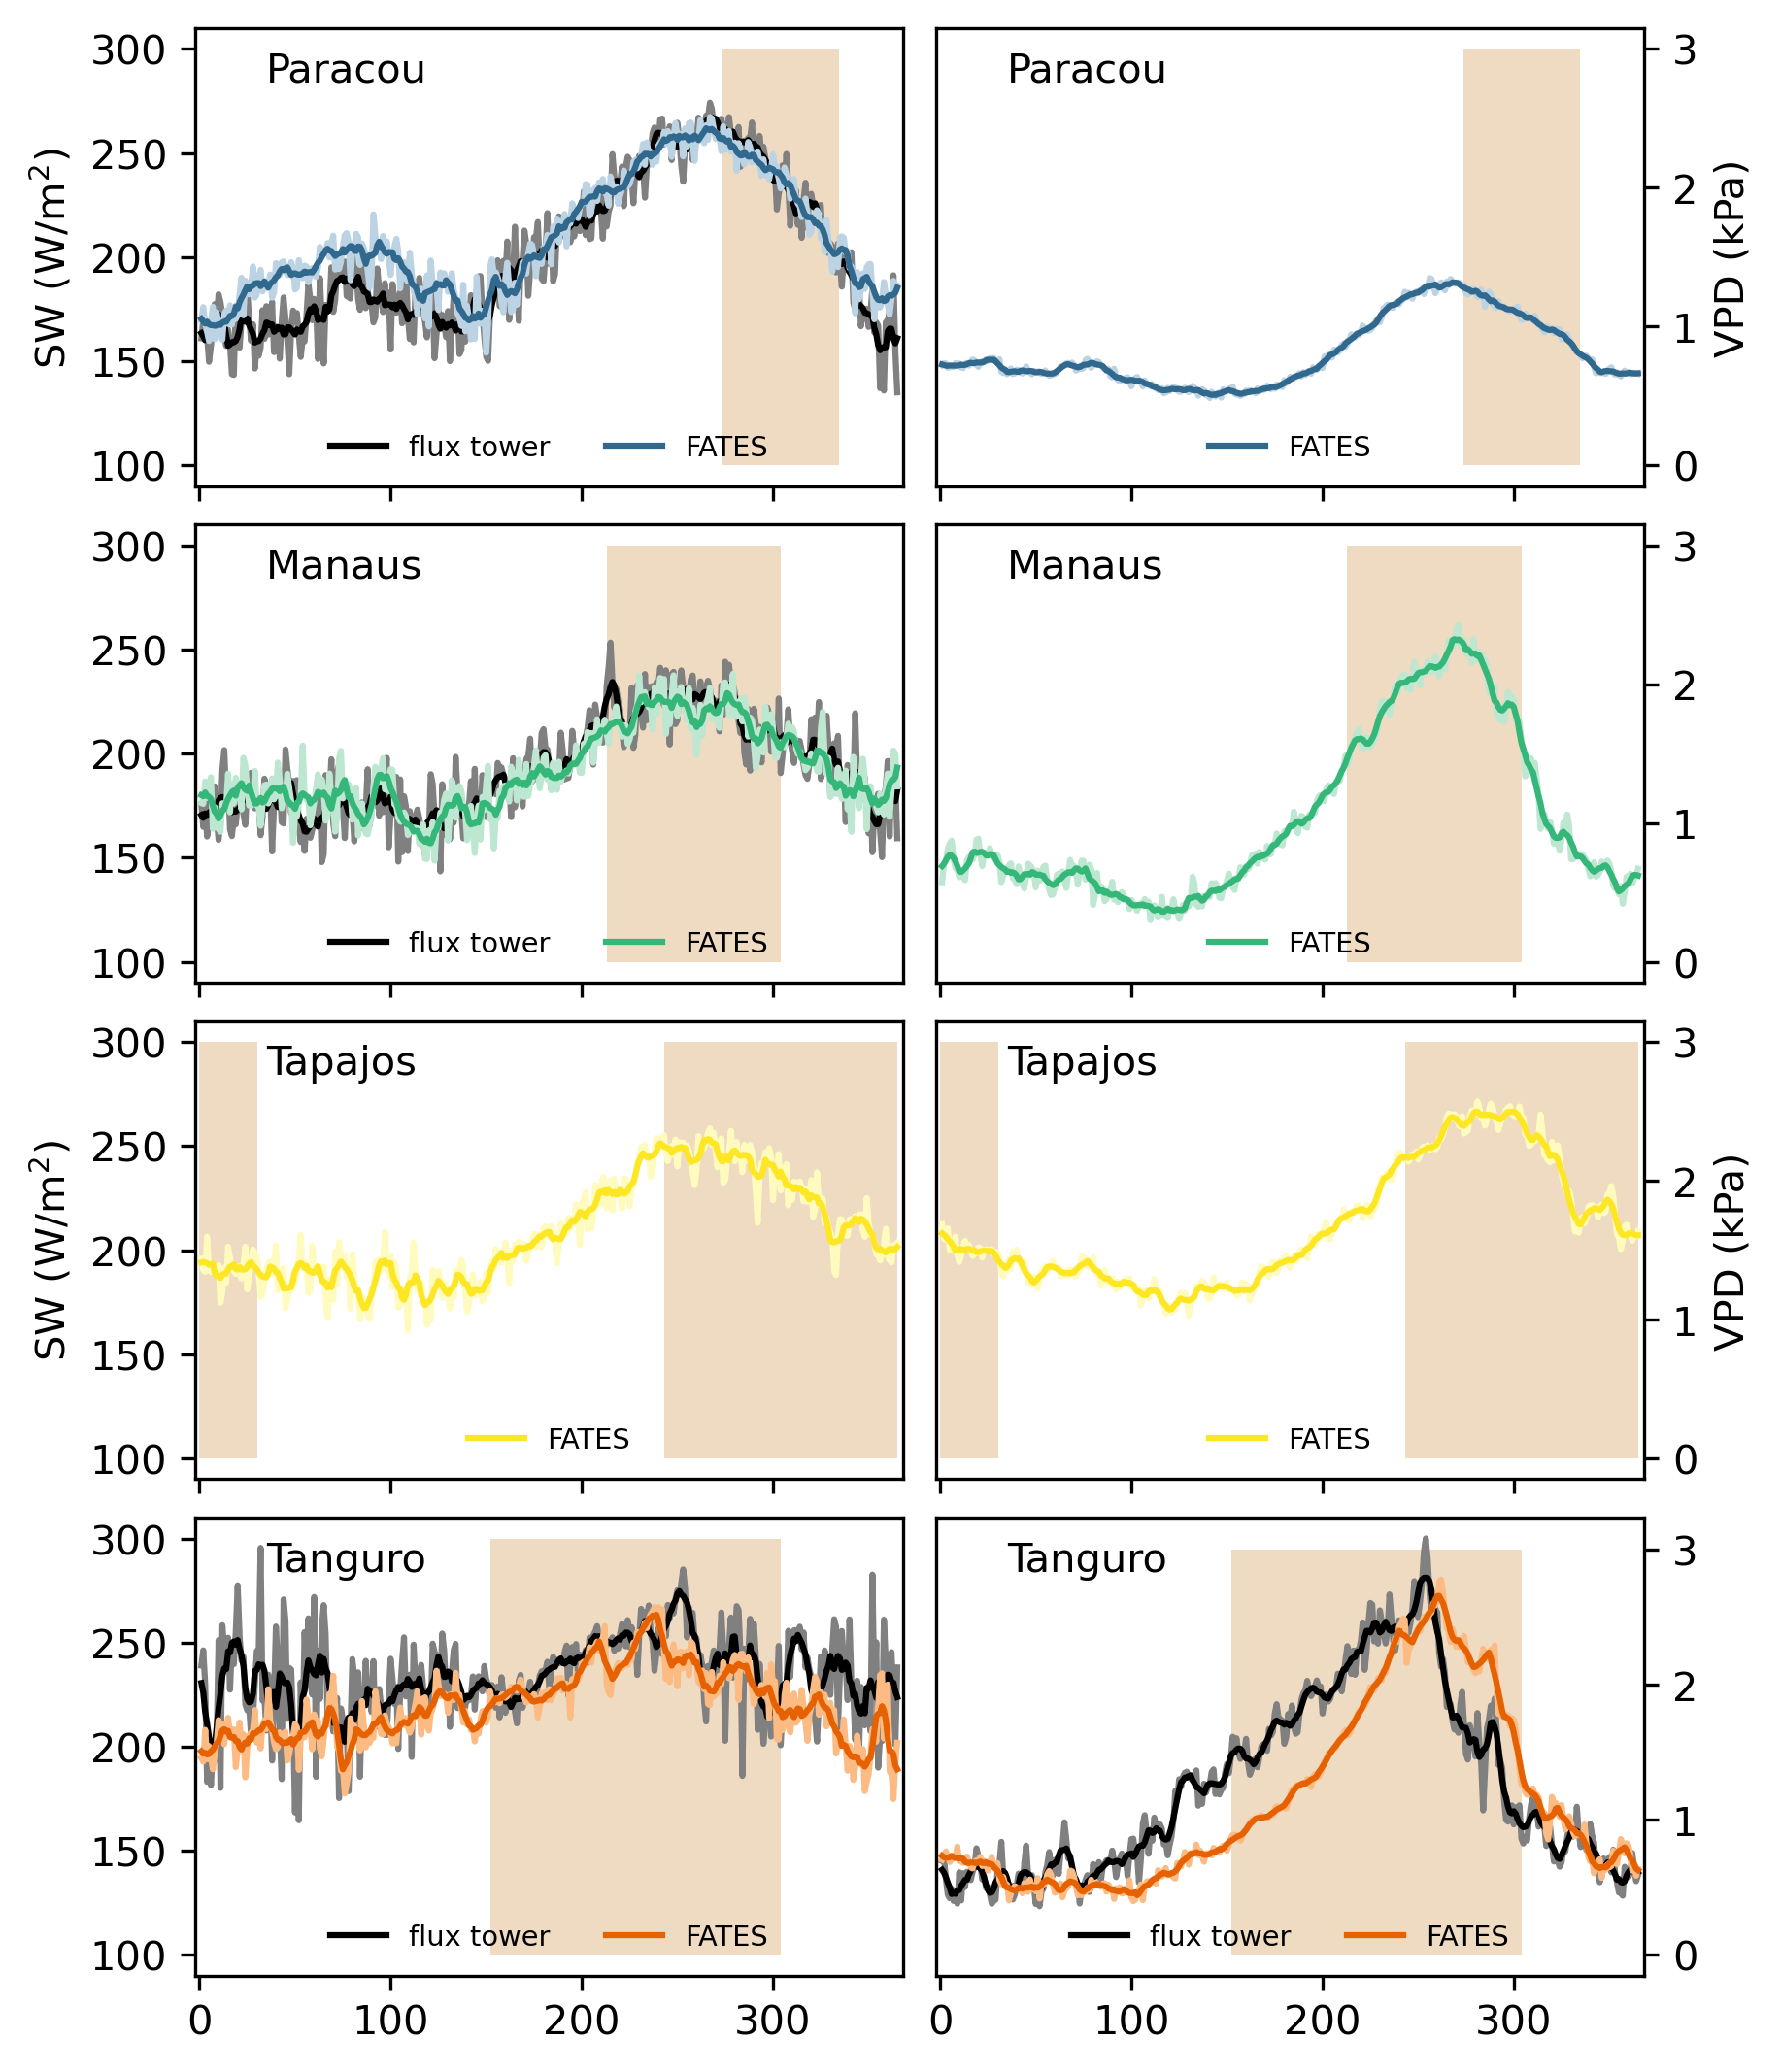

In [61]:
# Order from most to least mean annual rainfall
# add light brown bar showing dry season
# version without residuals

fig, axes = plt.subplots(4,2, figsize=(6,7), sharex=True)

# Columns = SW rad, VPD
# Rows = Paracou, Manaus (K34), Tapajos, Tanguro, residuals (all)

# color scheme: observations = black
# Custom 4-color palette from Wet to Dry
# Order: Paracou (wettest) -> Manaus -> Tapajos -> Tanguro (driest)
site_colors = ['#31688e', '#35b779', '#fde725','#e66101']
shading_colors = ['#bcd3e3', '#bee7d2','#fffbbf','#fdbb84']

### Row 1 - Paracou ###
# Col 1: rad
axes[0,0].add_patch(gswp_par_dry_rad)
axes[0,0].plot(par_jd, par_avg_rad, color="grey")
axes[0,0].plot(par_jd, uniform_filter1d(par_avg_rad, size=7), color="black", label="flux tower")
axes[0,0].plot(fates_days, all_sites_rad.sel(site="par").values, color=shading_colors[0])
axes[0,0].plot(fates_days, uniform_filter1d(all_sites_rad.sel(site="par").values, size=7), color=site_colors[0], label="FATES")
axes[0,0].set_ylabel('SW (W/m$^2$)')
axes[0,0].text(0.1, 0.95, 'Paracou', transform=axes[0,0].transAxes, va='top', ha='left')
axes[0,0].set_xlim(-2,368)
axes[0,0].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)
    
# Col 2: VPD
axes[0,1].add_patch(gswp_par_dry_vpd)
#axes[0,1].plot(par_jd, par_avg_vpd, color="grey")
#axes[0,1].plot(par_jd, uniform_filter1d(par_avg_vpd, size=7), color="black", label="flux tower")
axes[0,1].plot(fates_days, all_sites_vpd.sel(site="par").values, color=shading_colors[0])
axes[0,1].plot(fates_days, uniform_filter1d(all_sites_vpd.sel(site="par").values, size=7), color=site_colors[0], label="FATES")
axes[0,1].set_ylabel('VPD (kPa)')
axes[0,1].text(0.1, 0.95, 'Paracou', transform=axes[0,1].transAxes, va='top', ha='left')
axes[0,1].set_xlim(-2,368)
axes[0,1].yaxis.tick_right()                 # <-- Moves ticks right
axes[0,1].yaxis.set_label_position("right")  # <-- Moves label text right
axes[0,1].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

### Row 2 - K34 Manaus ###
## col 1: rad
axes[1,0].add_patch(gswp_k34_dry_rad)
axes[1,0].plot(k34_jd, k34_avg_rad, color="grey")
axes[1,0].plot(k34_jd, uniform_filter1d(k34_avg_rad, size=7), color="black", label="flux tower")
axes[1,0].plot(fates_days, all_sites_rad.sel(site="k34").values, color=shading_colors[1])
axes[1,0].plot(fates_days, uniform_filter1d(all_sites_rad.sel(site="k34").values, size=7), color=site_colors[1], label="FATES")
axes[1,0].text(0.1, 0.95, 'Manaus', transform=axes[1,0].transAxes, va='top', ha='left')
axes[1,0].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

## col 2: VPD
axes[1,1].add_patch(gswp_k34_dry_vpd)
#axes[1,1].plot(k34_jd, k34_avg_vpd, color="grey")
#axes[1,1].plot(k34_jd, uniform_filter1d(k34_avg_vpd, size=7), color="black", label="flux tower")
axes[1,1].plot(fates_days, all_sites_vpd.sel(site="k34").values, color=shading_colors[1])
axes[1,1].plot(fates_days, uniform_filter1d(all_sites_vpd.sel(site="k34").values, size=7), color=site_colors[1], label="FATES")
axes[1,1].text(0.1, 0.95, 'Manaus', transform=axes[1,1].transAxes, va='top', ha='left')
axes[1,1].yaxis.tick_right()                 # <-- Moves ticks right
axes[1,1].yaxis.set_label_position("right")  # <-- Moves label text right
axes[1,1].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

### Row 3 - Tapajos ###
## col 1: rad
axes[2,0].add_patch(gswp_tap_dry1_rad)
axes[2,0].add_patch(gswp_tap_dry2_rad)
#axes[2,0].plot(tap_jd, tap_avg_rad, color="grey")
#axes[2,0].plot(tap_jd, uniform_filter1d(tap_avg_rad, size=7), color="black", label="flux tower")
axes[2,0].plot(fates_days, all_sites_rad.sel(site="tap").values, color=shading_colors[2])
axes[2,0].plot(fates_days, uniform_filter1d(all_sites_rad.sel(site="tap").values, size=7), color=site_colors[2], label="FATES")
axes[2,0].set_ylabel('SW (W/m$^2$)')
axes[2,0].text(0.1, 0.95, 'Tapajos', transform=axes[2,0].transAxes, va='top', ha='left')
axes[2,0].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

## col 2: vpd
axes[2,1].add_patch(gswp_tap_dry1_vpd)
axes[2,1].add_patch(gswp_tap_dry2_vpd)
#axes[2,1].plot(tap_jd, tap_avg_vpd, color="grey")
#axes[2,1].plot(tap_jd, uniform_filter1d(tap_avg_vpd, size=7), color="black", label="flux tower")
axes[2,1].plot(fates_days, all_sites_vpd.sel(site="tap").values, color=shading_colors[2])
axes[2,1].plot(fates_days, uniform_filter1d(all_sites_vpd.sel(site="tap").values, size=7), color=site_colors[2], label="FATES")
axes[2,1].set_ylabel('VPD (kPa)')
axes[2,1].text(0.1, 0.95, 'Tapajos', transform=axes[2,1].transAxes, va='top', ha='left')
axes[2,1].yaxis.tick_right()                 # <-- Moves ticks right
axes[2,1].yaxis.set_label_position("right")  # <-- Moves label text right
axes[2,1].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

### Row 4 - Tanguro ###
## col 1: rad
axes[3,0].add_patch(gswp_tan_dry_rad)
axes[3,0].plot(tan_jd, tan_avg_rad, color="grey")
axes[3,0].plot(tan_jd, uniform_filter1d(tan_avg_rad, size=7), color="black", label="flux tower")
axes[3,0].plot(fates_days, all_sites_rad.sel(site="tan").values, color=shading_colors[3])
axes[3,0].plot(fates_days, uniform_filter1d(all_sites_rad.sel(site="tan").values, size=7), color=site_colors[3], label="FATES")
axes[3,0].text(0.1, 0.95, 'Tanguro', transform=axes[3,0].transAxes, va='top', ha='left')
axes[3,0].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

## col 2: VPD
axes[3,1].add_patch(gswp_tan_dry_vpd)
axes[3,1].plot(tan_jd, tan_avg_vpd, color="grey")
axes[3,1].plot(tan_jd, uniform_filter1d(tan_avg_vpd, size=7), color="black", label="flux tower")
axes[3,1].plot(fates_days, all_sites_vpd.sel(site="tan").values, color=shading_colors[3])
axes[3,1].plot(fates_days, uniform_filter1d(all_sites_vpd.sel(site="tan").values, size=7), color=site_colors[3], label="FATES")
axes[3,1].text(0.1, 0.95, 'Tanguro', transform=axes[3,1].transAxes, va='top', ha='left')
axes[3,1].yaxis.tick_right()                 # <-- Moves ticks right
axes[3,1].yaxis.set_label_position("right")  # <-- Moves label text right
axes[3,1].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)



plt.tight_layout()
plt.show()

In [ ]:
# Order from most to least mean annual rainfall
# add light brown bar showing dry season
# version with residuals

fig, axes = plt.subplots(5,2, figsize=(6,7), sharex=True)

# Columns = SW rad, VPD
# Rows = Paracou, Manaus (K34), Tapajos, Tanguro, residuals (all)

# color scheme: observations = black
# Custom 4-color palette from Wet to Dry
# Order: Paracou (wettest) -> Manaus -> Tapajos -> Tanguro (driest)
site_colors = ['#31688e', '#35b779', '#fde725','#e66101']
shading_colors = ['#bcd3e3', '#bee7d2','#fffbbf','#fdbb84']

### Row 1 - Paracou ###
# Col 1: rad
axes[0,0].add_patch(gswp_par_dry_rad)
axes[0,0].plot(par_jd, par_avg_rad, color="grey")
axes[0,0].plot(par_jd, uniform_filter1d(par_avg_rad, size=7), color="black", label="flux tower")
axes[0,0].plot(fates_days, fates_par_avg_rad, color=shading_colors[0])
axes[0,0].plot(fates_days, uniform_filter1d(fates_par_avg_rad, size=7), color=site_colors[0], label="FATES")
axes[0,0].set_ylabel('SW (W/m$^2$)')
axes[0,0].text(0.1, 0.95, 'Paracou', transform=axes[0,0].transAxes, va='top', ha='left')
axes[0,0].set_xlim(-2,368)
axes[0,0].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)
    
# Col 2: VPD
axes[0,1].add_patch(gswp_par_dry_vpd)
axes[0,1].plot(par_jd, par_avg_vpd, color="grey")
axes[0,1].plot(par_jd, uniform_filter1d(par_avg_vpd, size=7), color="black", label="flux tower")
axes[0,1].plot(fates_days, fates_par_avg_vpd, color=shading_colors[0])
axes[0,1].plot(fates_days, uniform_filter1d(fates_par_avg_vpd, size=7), color=site_colors[0], label="FATES")
axes[0,1].set_ylabel('VPD (kPa)')
axes[0,1].text(0.1, 0.95, 'Paracou', transform=axes[0,1].transAxes, va='top', ha='left')
axes[0,1].set_xlim(-2,368)
axes[0,1].yaxis.tick_right()                 # <-- Moves ticks right
axes[0,1].yaxis.set_label_position("right")  # <-- Moves label text right
axes[0,1].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

### Row 2 - K34 Manaus ###
## col 1: rad
axes[1,0].add_patch(gswp_k34_dry_rad)
axes[1,0].plot(k34_jd, k34_avg_rad, color="grey")
axes[1,0].plot(k34_jd, uniform_filter1d(k34_avg_rad, size=7), color="black", label="flux tower")
axes[1,0].plot(fates_days, fates_k34_avg_rad, color=shading_colors[1])
axes[1,0].plot(fates_days, uniform_filter1d(fates_k34_avg_rad, size=7), color=site_colors[1], label="FATES")
axes[1,0].text(0.1, 0.95, 'Manaus', transform=axes[1,0].transAxes, va='top', ha='left')
axes[1,0].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

## col 2: VPD
axes[1,1].add_patch(gswp_k34_dry_vpd)
axes[1,1].plot(k34_jd, k34_avg_vpd, color="grey")
axes[1,1].plot(k34_jd, uniform_filter1d(k34_avg_vpd, size=7), color="black", label="flux tower")
axes[1,1].plot(fates_days, fates_k34_avg_vpd, color=shading_colors[1])
axes[1,1].plot(fates_days, uniform_filter1d(fates_k34_avg_vpd, size=7), color=site_colors[1], label="FATES")
axes[1,1].text(0.1, 0.95, 'Manaus', transform=axes[1,1].transAxes, va='top', ha='left')
axes[1,1].yaxis.tick_right()                 # <-- Moves ticks right
axes[1,1].yaxis.set_label_position("right")  # <-- Moves label text right
axes[1,1].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

### Row 3 - Tapajos ###
## col 1: rad
axes[2,0].add_patch(gswp_tap_dry1_rad)
axes[2,0].add_patch(gswp_tap_dry2_rad)
axes[2,0].plot(tap_jd, tap_avg_rad, color="grey")
axes[2,0].plot(tap_jd, uniform_filter1d(tap_avg_rad, size=7), color="black", label="flux tower")
axes[2,0].plot(fates_days, fates_tap_avg_rad, color=shading_colors[2])
axes[2,0].plot(fates_days, uniform_filter1d(fates_tap_avg_rad, size=7), color=site_colors[2], label="FATES")
axes[2,0].set_ylabel('SW (W/m$^2$)')
axes[2,0].text(0.1, 0.95, 'Tapajos', transform=axes[2,0].transAxes, va='top', ha='left')
axes[2,0].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

## col 2: vpd
axes[2,1].add_patch(gswp_tap_dry1_vpd)
axes[2,1].add_patch(gswp_tap_dry2_vpd)
axes[2,1].plot(tap_jd, tap_avg_vpd, color="grey")
axes[2,1].plot(tap_jd, uniform_filter1d(tap_avg_vpd, size=7), color="black", label="flux tower")
axes[2,1].plot(fates_days, fates_tap_avg_vpd, color=shading_colors[2])
axes[2,1].plot(fates_days, uniform_filter1d(fates_tap_avg_vpd, size=7), color=site_colors[2], label="FATES")
axes[2,1].set_ylabel('VPD (kPa)')
axes[2,1].text(0.1, 0.95, 'Tapajos', transform=axes[2,1].transAxes, va='top', ha='left')
axes[2,1].yaxis.tick_right()                 # <-- Moves ticks right
axes[2,1].yaxis.set_label_position("right")  # <-- Moves label text right
axes[2,1].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

### Row 4 - Tanguro ###
## col 1: rad
axes[3,0].add_patch(gswp_tan_dry_rad)
axes[3,0].plot(tan_jd, tan_avg_rad, color="grey")
axes[3,0].plot(tan_jd, uniform_filter1d(tan_avg_rad, size=7), color="black", label="flux tower")
axes[3,0].plot(fates_days, fates_tan_avg_rad, color=shading_colors[3])
axes[3,0].plot(fates_days, uniform_filter1d(fates_tan_avg_rad, size=7), color=site_colors[3], label="FATES")
axes[3,0].text(0.1, 0.95, 'Tanguro', transform=axes[3,0].transAxes, va='top', ha='left')
axes[3,0].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

## col 2: VPD
axes[3,1].add_patch(gswp_tan_dry_vpd)
axes[3,1].plot(tan_jd, tan_avg_vpd, color="grey")
axes[3,1].plot(tan_jd, uniform_filter1d(tan_avg_vpd, size=7), color="black", label="flux tower")
axes[3,1].plot(fates_days, fates_tan_avg_vpd, color=shading_colors[3])
axes[3,1].plot(fates_days, uniform_filter1d(fates_tan_avg_vpd, size=7), color=site_colors[3], label="FATES")
axes[3,1].text(0.1, 0.95, 'Tanguro', transform=axes[3,1].transAxes, va='top', ha='left')
axes[3,1].yaxis.tick_right()                 # <-- Moves ticks right
axes[3,1].yaxis.set_label_position("right")  # <-- Moves label text right
axes[3,1].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

## row 5: residuals
## col 1: rad
axes[4,0].plot(par_jd, uniform_filter1d(100.*(fates_par_avg_rad-par_avg_rad)/(par_avg_rad),size=7), color=site_colors[0],label='Paracou')
axes[4,0].plot(k34_jd, uniform_filter1d(100.*(fates_k34_avg_rad-k34_avg_rad)/(k34_avg_rad),size=7), color=site_colors[1],label='Manaus')
axes[4,0].plot(tap_jd, uniform_filter1d(100.*(fates_tap_avg_rad-tap_avg_rad)/(tap_avg_rad),size=7), color=site_colors[2],label='Tapajos')
axes[4,0].plot(tan_jd, uniform_filter1d(100.*(fates_tan_avg_rad-tan_avg_rad)/(tan_avg_rad),size=7), color=site_colors[3],label='Tanguro')
axes[4,0].set_ylabel('SW % diff.')
axes[4,0].plot(par_jd, 0.*par_jd, color="black",linestyle="dotted")
axes[4,0].set_xlabel('DOY')
axes[4,0].legend(loc='upper left',fontsize='x-small',frameon=False)

## col 2: VPD
axes[4,1].plot(par_jd, uniform_filter1d(100.*(fates_par_avg_vpd-par_avg_vpd)/par_avg_vpd,size=7), color=site_colors[0])
axes[4,1].plot(k34_jd, uniform_filter1d(100.*(fates_k34_avg_vpd-k34_avg_vpd)/k34_avg_vpd,size=7), color=site_colors[1])
axes[4,1].plot(tap_jd, uniform_filter1d(100.*(fates_tap_avg_vpd-tap_avg_vpd)/tap_avg_vpd,size=7), color=site_colors[2])
axes[4,1].plot(tan_jd, uniform_filter1d(100.*(fates_tan_avg_vpd-tan_avg_vpd)/tan_avg_vpd,size=7), color=site_colors[3])
axes[4,1].set_ylabel('VPD % diff.')
axes[4,1].plot(k34_jd, 0.*k34_jd, color="black",linestyle="dotted")
axes[4,1].set_xlabel('DOY')
axes[4,1].yaxis.tick_right()                 # <-- Moves ticks right
axes[4,1].yaxis.set_label_position("right")  # <-- Moves label text right


plt.tight_layout()
plt.show()

In [ ]:
# plot one figure with FATES SW at each site

plt.plot(fates_days, fates_par_avg_rad, color=shading_colors[0])
plt.plot(fates_days, uniform_filter1d(fates_par_avg_rad, size=7), color=site_colors[0], label="Paracou")
plt.ylabel('FATES Incident Solar Radiation (W/m$^2$)')
plt.xlim(-2,368)
plt.plot(fates_days, fates_k34_avg_rad, color=shading_colors[1])
plt.plot(fates_days, uniform_filter1d(fates_k34_avg_rad, size=7), color=site_colors[1], label="Manaus")
plt.plot(fates_days, fates_tap_avg_rad, color=shading_colors[2])
plt.plot(fates_days, uniform_filter1d(fates_tap_avg_rad, size=7), color=site_colors[2], label="Tapajos")
plt.plot(fates_days, fates_tan_avg_rad, color=shading_colors[3])
plt.plot(fates_days, uniform_filter1d(fates_tan_avg_rad, size=7), color=site_colors[3], label="Tanguro")
